# 🚦 Step 2 — Advanced Traffic Sign Recognition Model (GTSRB)

**Reference:** your `Practical-5(a)(3).ipynb` notebook. The training sequence remains familiar: **imports → device → dataset → model → dataloaders → loss → Stage 1 → Stage 2 → graphs → test → save / predict**.

**Improvements:** validation split by traffic-sign track, sign-safe augmentation (no horizontal flip), pretrained **MobileNetV3-Large** by default for future video inference, optional ResNet-18, AdamW + cosine annealing, early stopping, best checkpoint, F1/precision/recall, confusion matrix, inference demo.

**First:** run `dataset_setup.ipynb`. All three distributed files must stay together. Dataset download creates `data2/` automatically. Trained model weights save to `gtsrb_best_model.pth` after training.

> This is a cropped-sign **classifier**, not a video sign detector. Video detection is the next stage.

## 1. Import Python libraries and configure the experiment

In [1]:
import copy
import random
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score)
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import MobileNet_V3_Large_Weights, ResNet18_Weights
from tqdm.auto import tqdm

# Configurable settings. Start small; increase fine-tuning epochs if desired.
SEED = 42
DATA_DIR = Path("./data2")
MODEL_NAME = "mobilenet_v3_large"  # Alternatives: "resnet18"
NUM_CLASSES = 43
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS_STAGE1 = 3
EPOCHS_STAGE2 = 10
EARLY_STOP_PATIENCE = 4
BEST_PATH = Path("gtsrb_best_model.pth")
MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)

# Official GTSRB class-ID order; useful for future video voice alerts.
CLASS_NAMES = [
    "Speed limit 20 km/h", "Speed limit 30 km/h", "Speed limit 50 km/h",
    "Speed limit 60 km/h", "Speed limit 70 km/h", "Speed limit 80 km/h",
    "End of speed limit 80 km/h", "Speed limit 100 km/h",
    "Speed limit 120 km/h", "No passing",
    "No passing for vehicles over 3.5 tonnes",
    "Right-of-way at next intersection", "Priority road", "Yield", "Stop",
    "No vehicles", "Vehicles over 3.5 tonnes prohibited", "No entry",
    "General caution", "Dangerous curve left", "Dangerous curve right",
    "Double curve", "Bumpy road", "Slippery road",
    "Road narrows on the right", "Road work", "Traffic signals",
    "Pedestrians", "Children crossing", "Bicycles crossing",
    "Beware of ice or snow", "Wild animals crossing",
    "End of all speed and passing limits", "Turn right ahead",
    "Turn left ahead", "Ahead only", "Go straight or right",
    "Go straight or left", "Keep right", "Keep left",
    "Roundabout mandatory", "End of no passing",
    "End of no passing for vehicles over 3.5 tonnes",
]
assert len(CLASS_NAMES) == NUM_CLASSES

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)
print("Model:", MODEL_NAME)


PyTorch: 2.12.1
Model: mobilenet_v3_large


/Users/neev/ml/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Select GPU or CPU (Apple Silicon MPS supported)

In [2]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Training on:", device)

# DataLoader workers=0 is reliable inside Jupyter on macOS.
NUM_WORKERS = 0
PIN_MEMORY = (device.type == "cuda")


Training on: mps


## 3. Dataset transforms (without inappropriate horizontal flipping)

In [3]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomApply([transforms.ColorJitter(
        brightness=0.20, contrast=0.20, saturation=0.15)], p=0.70),
    transforms.RandomRotation(8),             # Small camera rotation only
    transforms.RandomAffine(degrees=0, translate=(0.06, 0.06), scale=(0.90, 1.10)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

print("Augmentation: small rotation, affine, lighting — no horizontal/vertical flip")


Augmentation: small rotation, affine, lighting — no horizontal/vertical flip


## 4. Load the downloaded dataset (train/validation/test)

In [4]:
# Two views of the *same* training images with different transforms.
train_all = datasets.GTSRB(root=str(DATA_DIR), split="train",
                          download=False, transform=train_transform)
val_all = datasets.GTSRB(root=str(DATA_DIR), split="train",
                        download=False, transform=eval_transform)
test_data = datasets.GTSRB(root=str(DATA_DIR), split="test",
                          download=False, transform=eval_transform)

assert len(train_all) == len(val_all)
print("Total official training:", len(train_all))
print("Official test images:  ", len(test_data))
print("Class count:           ", NUM_CLASSES)


Total official training: 26640
Official test images:   12630
Class count:            43


## 5. Create a reproducible validation split

Unlike the reference notebook, **do not tune on the official test set**. GTSRB has multiple images of the same physical sign in a tracking sequence. Group samples by sign/track ID so a single sign's frames don't appear in both training and validation. This reduces leakage.

In [5]:
# torchvision's training filenames resemble: Training/00014/00000_00000.ppm
# The first filename number identifies the tracked sign within its class.
tracks_by_class = defaultdict(lambda: defaultdict(list))
for idx, (path, label) in enumerate(train_all._samples):
    track_id = Path(path).stem.split("_")[0]
    tracks_by_class[int(label)][track_id].append(idx)

rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for label in range(NUM_CLASSES):
    groups = list(tracks_by_class[label].values())
    if len(groups) < 2:
        raise RuntimeError(f"Class {label} has fewer than two tracks; cannot split safely")
    rng.shuffle(groups)
    n_val = min(max(1, round(len(groups) * 0.20)), len(groups) - 1)
    val_idx.extend(i for group in groups[:n_val] for i in group)
    train_idx.extend(i for group in groups[n_val:] for i in group)

assert set(train_idx).isdisjoint(val_idx)
train_data = Subset(train_all, train_idx)
val_data = Subset(val_all, val_idx)
print(f"Train: {len(train_data):,} | Validation: {len(val_data):,} | Test: {len(test_data):,}")
print("Validation is grouped by tracking sequence and includes every class.")


Train: 21,360 | Validation: 5,280 | Test: 12,630
Validation is grouped by tracking sequence and includes every class.


## 6. Create the DataLoaders

In [6]:
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
print("Train batches:", len(train_loader), "Val batches:", len(val_loader))


Train batches: 668 Val batches: 165


## 7. Display sample signs and class IDs

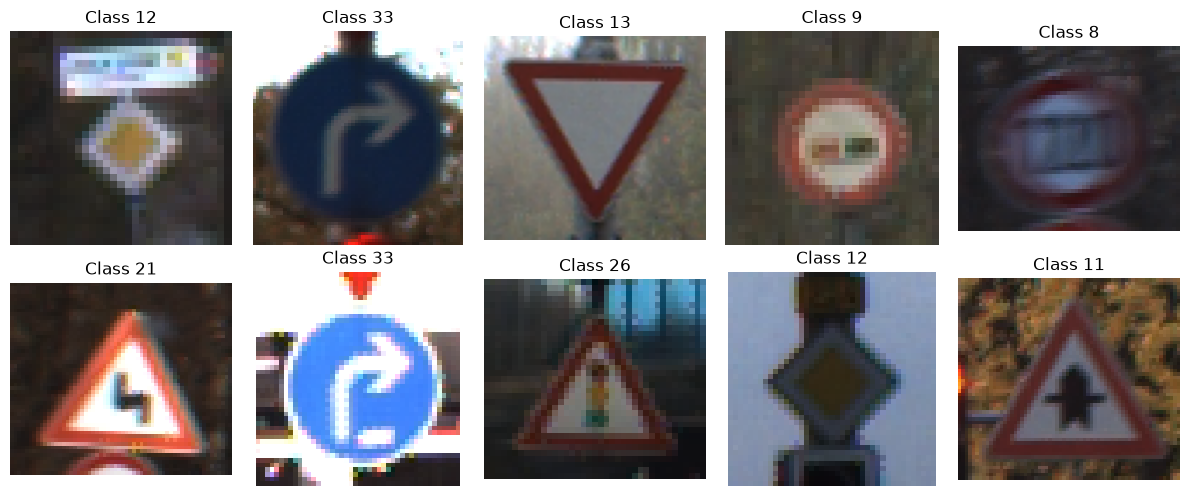

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, sample_i in zip(axes.flat, rng.choice(len(train_all), size=10, replace=False)):
    path, class_id = train_all._samples[int(sample_i)]
    with Image.open(path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"Class {class_id}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 8. Build a pretrained model with 43 traffic sign classes

In [8]:
def build_model(name, pretrained=True):
    if name == "mobilenet_v3_large":
        weights = MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
        net = models.mobilenet_v3_large(weights=weights)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, NUM_CLASSES)
    elif name == "resnet18":
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        net = models.resnet18(weights=weights)
        net.fc = nn.Sequential(
            nn.Linear(net.fc.in_features, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(256, NUM_CLASSES)
        )
    else:
        raise ValueError("MODEL_NAME must be 'mobilenet_v3_large' or 'resnet18'")
    return net

model = build_model(MODEL_NAME, pretrained=True).to(device)
params = sum(p.numel() for p in model.parameters())
print(f"Loaded {MODEL_NAME} | {params / 1_000_000:.2f} million parameters")


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /Users/neev/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:05<00:00, 4.00MB/s]


Loaded mobilenet_v3_large | 4.26 million parameters


## 9. Loss function, training, evaluation and best-checkpoint helpers

In [9]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
history = []
best_val_acc = -1.0
best_epoch = None

def select_trainable(stage):
    """Stage 1: train head only. Stage 2: fine-tune last backbone blocks + head."""
    for p in model.parameters():
        p.requires_grad = False
    if MODEL_NAME == "mobilenet_v3_large":
        for p in model.classifier.parameters():
            p.requires_grad = True
        if stage == 2:
            for block in model.features[-3:]:
                for p in block.parameters():
                    p.requires_grad = True
    else:
        for p in model.fc.parameters():
            p.requires_grad = True
        if stage == 2:
            for p in model.layer4.parameters():
                p.requires_grad = True
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Stage {stage}: {n:,} trainable parameters")


def freeze_inactive_bn():
    """Keep frozen backbone BatchNorm statistics unchanged during training."""
    for layer in model.modules():
        if isinstance(layer, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in layer.parameters(recurse=False)):
                layer.eval()


def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        freeze_inactive_bn()
    total_loss = correct = seen = 0
    iterator = tqdm(loader, leave=False, desc="Train" if training else "Evaluate")
    with torch.enable_grad() if training else torch.inference_mode():
        for images, labels in iterator:
            images = images.to(device, non_blocking=PIN_MEMORY)
            labels = labels.to(device, non_blocking=PIN_MEMORY)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
                logits = model(images)
                loss = criterion(logits, labels)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad], max_norm=2.0)
                optimizer.step()
            n = labels.size(0)
            seen += n
            total_loss += loss.item() * n
            correct += (logits.argmax(dim=1) == labels).sum().item()
    return total_loss / seen, 100 * correct / seen


def save_if_best(stage, epoch, validation_accuracy):
    global best_val_acc, best_epoch
    if validation_accuracy > best_val_acc:
        best_val_acc = validation_accuracy
        best_epoch = (stage, epoch)
        torch.save({
            "model_name": MODEL_NAME,
            "model_state_dict": model.state_dict(),
            "num_classes": NUM_CLASSES,
            "image_size": IMAGE_SIZE,
            "mean": MEAN,
            "std": STD,
            "best_val_accuracy": float(best_val_acc),
            "class_names": CLASS_NAMES,
            "stage": stage,
            "epoch": epoch,
        }, BEST_PATH)
        print(f"  ✅ Saved best weights: {BEST_PATH} (val accuracy {best_val_acc:.2f}%)")
        return True
    return False


## 10. Stage 1 — Feature extraction (classifier head only)

In [10]:
select_trainable(stage=1)
optimizer1 = optim.AdamW(
    [p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-4)
scheduler1 = optim.lr_scheduler.CosineAnnealingLR(optimizer1, T_max=max(1, EPOCHS_STAGE1))

for epoch in range(1, EPOCHS_STAGE1 + 1):
    train_loss, train_acc = run_epoch(train_loader, optimizer1)
    val_loss, val_acc = run_epoch(val_loader)
    scheduler1.step()
    history.append({"stage": 1, "epoch": epoch, "train_loss": train_loss,
                    "train_acc": train_acc, "val_loss": val_loss, "val_acc": val_acc})
    save_if_best(1, epoch, val_acc)
    print(f"Stage 1 [{epoch}/{EPOCHS_STAGE1}] | train loss {train_loss:.4f} | "
          f"train {train_acc:.2f}% | val loss {val_loss:.4f} | val {val_acc:.2f}%")


Stage 1: 1,285,163 trainable parameters


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 69.07%)
Stage 1 [1/3] | train loss 1.0235 | train 80.62% | val loss 1.3831 | val 69.07%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 71.27%)
Stage 1 [2/3] | train loss 0.6011 | train 95.24% | val loss 1.3472 | val 71.27%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 72.25%)
Stage 1 [3/3] | train loss 0.5294 | train 97.77% | val loss 1.3101 | val 72.25%


## 11. Stage 2 — Fine-tune the last backbone blocks and classifier

In [11]:
# Resume the best stage-1 checkpoint, not necessarily the final stage-1 epoch.
checkpoint = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
select_trainable(stage=2)

if MODEL_NAME == "mobilenet_v3_large":
    backbone_params = [p for p in model.features[-3:].parameters() if p.requires_grad]
    head_params = list(model.classifier.parameters())
else:
    backbone_params = list(model.layer4.parameters())
    head_params = list(model.fc.parameters())

optimizer2 = optim.AdamW([
    {"params": backbone_params, "lr": 1e-5},
    {"params": head_params, "lr": 1e-4},
], weight_decay=1e-4)
scheduler2 = optim.lr_scheduler.CosineAnnealingLR(optimizer2, T_max=max(1, EPOCHS_STAGE2))

stale_epochs = 0
for epoch in range(1, EPOCHS_STAGE2 + 1):
    train_loss, train_acc = run_epoch(train_loader, optimizer2)
    val_loss, val_acc = run_epoch(val_loader)
    scheduler2.step()
    history.append({"stage": 2, "epoch": epoch, "train_loss": train_loss,
                    "train_acc": train_acc, "val_loss": val_loss, "val_acc": val_acc})
    improved = save_if_best(2, epoch, val_acc)
    stale_epochs = 0 if improved else stale_epochs + 1
    print(f"Stage 2 [{epoch}/{EPOCHS_STAGE2}] | train loss {train_loss:.4f} | "
          f"train {train_acc:.2f}% | val loss {val_loss:.4f} | val {val_acc:.2f}%")
    if stale_epochs >= EARLY_STOP_PATIENCE:
        print("Early stopping: validation accuracy has stopped improving")
        break
print("Best validation accuracy:", round(best_val_acc, 2), "%", "at", best_epoch)


Stage 2: 3,035,403 trainable parameters


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 76.88%)
Stage 2 [1/10] | train loss 0.6557 | train 93.83% | val loss 1.1587 | val 76.88%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 78.75%)
Stage 2 [2/10] | train loss 0.5393 | train 97.29% | val loss 1.0951 | val 78.75%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 80.28%)
Stage 2 [3/10] | train loss 0.5032 | train 98.51% | val loss 1.0541 | val 80.28%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 81.23%)
Stage 2 [4/10] | train loss 0.4871 | train 98.81% | val loss 1.0410 | val 81.23%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 81.27%)
Stage 2 [5/10] | train loss 0.4748 | train 98.97% | val loss 1.0320 | val 81.27%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 82.06%)
Stage 2 [6/10] | train loss 0.4654 | train 99.39% | val loss 1.0201 | val 82.06%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 82.37%)
Stage 2 [7/10] | train loss 0.4601 | train 99.44% | val loss 1.0158 | val 82.37%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 82.61%)
Stage 2 [8/10] | train loss 0.4556 | train 99.57% | val loss 1.0057 | val 82.61%


  ✅ Saved best weights: gtsrb_best_model.pth (val accuracy 82.65%)
Stage 2 [9/10] | train loss 0.4529 | train 99.61% | val loss 1.0033 | val 82.65%


Stage 2 [10/10] | train loss 0.4546 | train 99.49% | val loss 1.0036 | val 82.63%
Best validation accuracy: 82.65 % at (2, 9)


## 12. Plot actual training and validation performance

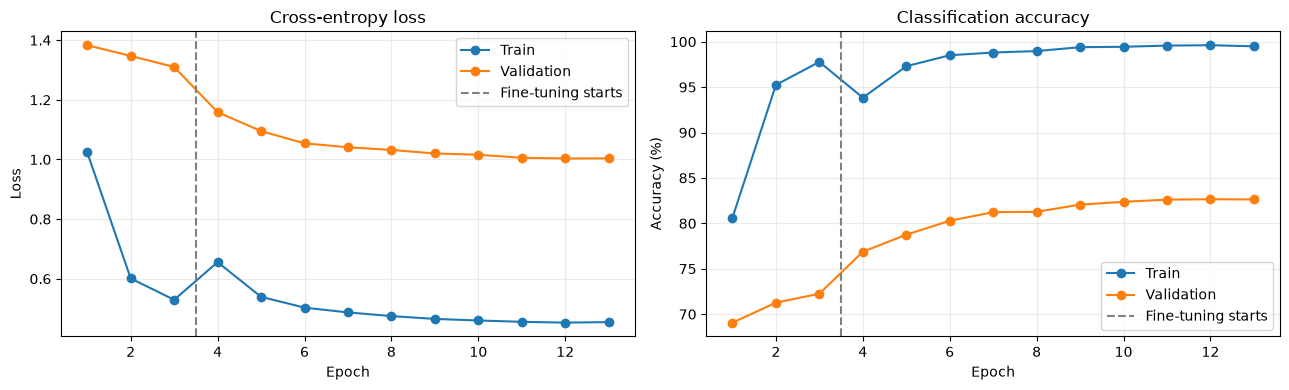

In [12]:
x = np.arange(1, len(history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(x, [h["train_loss"] for h in history], marker="o", label="Train")
axes[0].plot(x, [h["val_loss"] for h in history], marker="o", label="Validation")
axes[0].set(title="Cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[1].plot(x, [h["train_acc"] for h in history], marker="o", label="Train")
axes[1].plot(x, [h["val_acc"] for h in history], marker="o", label="Validation")
axes[1].set(title="Classification accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
stage1_epochs = sum(h["stage"] == 1 for h in history)
for ax in axes:
    ax.axvline(stage1_epochs + 0.5, linestyle="--", color="gray", label="Fine-tuning starts")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 13. Final official test evaluation (run after training)

The official test set was **not used** for training, early stopping, or selecting the checkpoint. We now load the best validation checkpoint and evaluate it once.

In [13]:
best_checkpoint = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.to(device).eval()

all_true, all_pred = [], []
with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc="Final test"):
        images = images.to(device, non_blocking=PIN_MEMORY)
        logits = model(images)
        all_true.extend(labels.numpy().tolist())
        all_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())

print("=" * 45)
print("OFFICIAL GTSRB TEST RESULTS")
print("Model:       ", MODEL_NAME)
print(f"Accuracy:     {accuracy_score(all_true, all_pred) * 100:.2f}%")
print(f"Precision:    {precision_score(all_true, all_pred, average='macro', zero_division=0) * 100:.2f}%")
print(f"Recall:       {recall_score(all_true, all_pred, average='macro', zero_division=0) * 100:.2f}%")
print(f"Macro F1:     {f1_score(all_true, all_pred, average='macro', zero_division=0) * 100:.2f}%")
print("Best val:    ", f"{best_checkpoint['best_val_accuracy']:.2f}%")
print("=" * 45)


Final test: 100%|██████████| 395/395 [00:30<00:00, 13.11it/s]

OFFICIAL GTSRB TEST RESULTS
Model:        mobilenet_v3_large
Accuracy:     84.04%
Precision:    78.67%
Recall:       74.86%
Macro F1:     75.79%
Best val:     82.65%


## 14. Confusion matrix

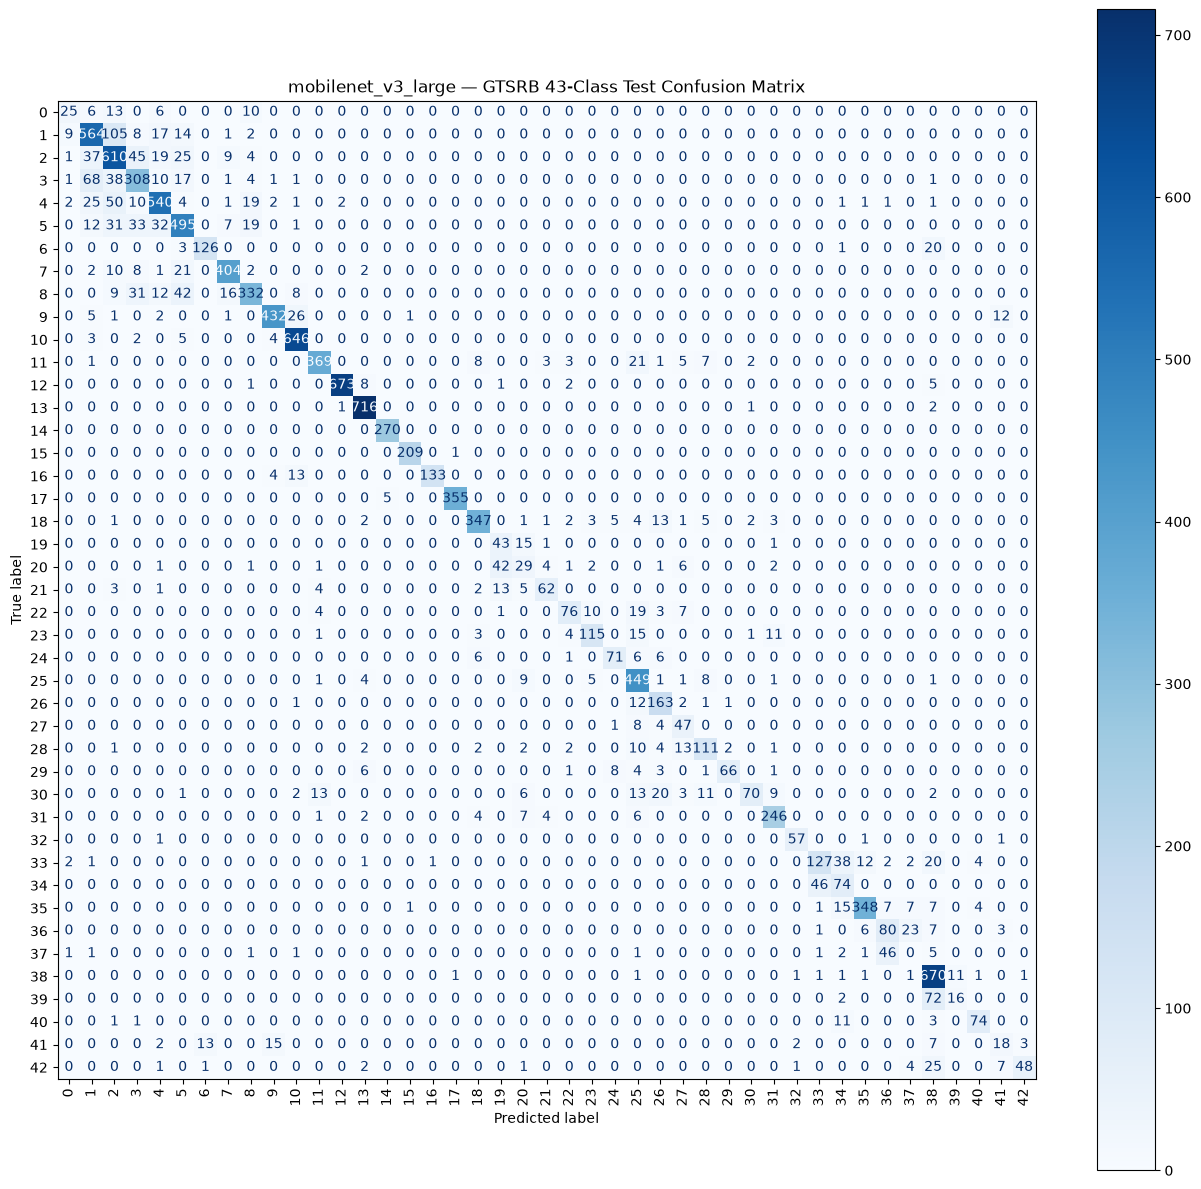

In [14]:
cm = confusion_matrix(all_true, all_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(13, 12))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(NUM_CLASSES)).plot(
    ax=ax, cmap="Blues", colorbar=True, values_format="d", xticks_rotation=90)
ax.set_title(f"{MODEL_NAME} — GTSRB 43-Class Test Confusion Matrix")
plt.tight_layout()
plt.show()


## 15. Detailed class-wise report

In [15]:
print(classification_report(all_true, all_pred,
                            labels=list(range(NUM_CLASSES)), zero_division=0, digits=3))


              precision    recall  f1-score   support

           0      0.610     0.417     0.495        60
           1      0.778     0.783     0.781       720
           2      0.699     0.813     0.752       750
           3      0.691     0.684     0.688       450
           4      0.837     0.818     0.828       660
           5      0.789     0.786     0.788       630
           6      0.900     0.840     0.869       150
           7      0.918     0.898     0.908       450
           8      0.841     0.738     0.786       450
           9      0.943     0.900     0.921       480
          10      0.923     0.979     0.950       660
          11      0.937     0.879     0.907       420
          12      0.996     0.975     0.985       690
          13      0.961     0.994     0.977       720
          14      0.982     1.000     0.991       270
          15      0.991     0.995     0.993       210
          16      0.993     0.887     0.937       150
          17      0.994    

## 16. Inference demo — classify an individual cropped sign

The final checkpoint `gtsrb_best_model.pth` includes the architecture and preprocessing parameters so it can be reused in the future video project. **Give it cropped traffic signs, not whole road frames.**

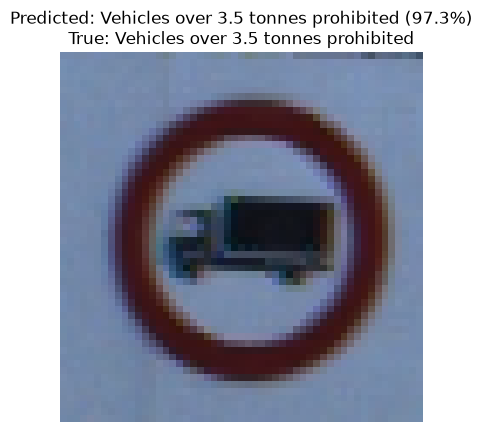

Saved model: /Users/neev/Downloads/DL/gtsrb_best_model.pth


In [16]:
# Rebuild architecture from the saved checkpoint (no ImageNet download required).
loaded = torch.load(BEST_PATH, map_location="cpu", weights_only=True)
predictor = build_model(loaded["model_name"], pretrained=False)
predictor.load_state_dict(loaded["model_state_dict"])
predictor = predictor.to(device).eval()

# Example: predict first official test image using the SAME normalization as training.
image, true_label = datasets.GTSRB(root=str(DATA_DIR), split="test", download=False)[0]
x_image = eval_transform(image).unsqueeze(0).to(device)
with torch.inference_mode():
    probability = predictor(x_image).softmax(dim=1)[0]
    predicted_id = int(probability.argmax().item())
    confidence = float(probability.max().item())

plt.imshow(image)
plt.axis("off")
plt.title(f"Predicted: {CLASS_NAMES[predicted_id]} ({confidence:.1%})\nTrue: {CLASS_NAMES[true_label]}")
plt.show()
print("Saved model:", BEST_PATH.resolve())


## ✅ Ready for the video stage

The **three source files** you need are `dataset_setup.ipynb`, `train_model.ipynb`, and `requirements.txt`. Running them creates (automatically) the downloaded dataset and `gtsrb_best_model.pth` weights.

**Video integration later:** detect and crop traffic signs from each road-video frame using a detection method (for example a traffic-sign-specific YOLO detector), then classify each crop with this checkpoint, and announce stable predictions. **This classifier alone cannot locate traffic signs in an entire video frame.**